# ROC- und Precision-Recall-Vergleich – praktischer Arbeitsstand

Wir untersuchen **simulierte Scorequellen A und B** für dieselben binär gelabelten Fälle. Die Scores sind keine kalibrierten Wahrscheinlichkeiten und die beiden Quellen keine trainierten Modelle. Nach einem Schwellenbeispiel vergleichen wir ROC- und PR-Messpunkte sowie ROC-AUC und Average Precision bei zwei Klassenverteilungen.

Bei der selten-positiven Verteilung werden negative Label-Score-Paare wiederholt. Dadurch entstehen **keine neuen unabhängigen Bilder**. Das Experiment illustriert Metriken; es ist noch keine vollständige Dokumentation oder Präsentation.

In [1]:
# 1 = gesuchtes Objekt vorhanden, 0 = Objekt fehlt
y_true = [1, 0, 1, 0, 0, 0, 1, 0]

# Simulierte Modell-Scores, keine nachgewiesenen Wahrscheinlichkeiten
scores = [0.95, 0.80, 0.70, 0.60, 0.40, 0.30, 0.20, 0.10]

# Ab dieser Schwelle lautet die Vorhersage: Objekt vorhanden
schwelle = 0.2
y_pred = [int(score >= schwelle) for score in scores]

for nummer, (wahr, score, vorhersage) in enumerate(
    zip(y_true, scores, y_pred), start=1
):
    print(
        f"Bild {nummer}: Wahrheit={wahr}, "
        f"Score={score:.2f}, Vorhersage={vorhersage}"
    )


Bild 1: Wahrheit=1, Score=0.95, Vorhersage=1
Bild 2: Wahrheit=0, Score=0.80, Vorhersage=1
Bild 3: Wahrheit=1, Score=0.70, Vorhersage=1
Bild 4: Wahrheit=0, Score=0.60, Vorhersage=1
Bild 5: Wahrheit=0, Score=0.40, Vorhersage=1
Bild 6: Wahrheit=0, Score=0.30, Vorhersage=1
Bild 7: Wahrheit=1, Score=0.20, Vorhersage=1
Bild 8: Wahrheit=0, Score=0.10, Vorhersage=0


In [2]:
# Die vier möglichen Ergebnisse zählen
tp = sum(w == 1 and p == 1 for w, p in zip(y_true, y_pred))
fp = sum(w == 0 and p == 1 for w, p in zip(y_true, y_pred))
fn = sum(w == 1 and p == 0 for w, p in zip(y_true, y_pred))
tn = sum(w == 0 and p == 0 for w, p in zip(y_true, y_pred))

precision = tp / (tp + fp)
recall = tp / (tp + fn)
fpr = fp / (fp + tn)

print(f"Precision: {precision:.1%}")
print(f"Recall: {recall:.1%}")
print(f"False Positive Rate: {fpr:.1%}")

Precision: 42.9%
Recall: 100.0%
False Positive Rate: 80.0%


In [3]:
ergebnisse = []

for schwelle in sorted(set(scores), reverse=True):
    y_pred = [int(score >= schwelle) for score in scores]

    tp = sum(w == 1 and p == 1 for w, p in zip(y_true, y_pred))
    fp = sum(w == 0 and p == 1 for w, p in zip(y_true, y_pred))
    fn = sum(w == 1 and p == 0 for w, p in zip(y_true, y_pred))
    tn = sum(w == 0 and p == 0 for w, p in zip(y_true, y_pred))

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    fpr = fp / (fp + tn)

    ergebnisse.append((schwelle, fpr, recall, precision))

    print(
        f"Schwelle {schwelle:.2f}: "
        f"Precision={precision:.1%}, "
        f"Recall={recall:.1%}, FPR={fpr:.1%}"
    )

Schwelle 0.95: Precision=100.0%, Recall=33.3%, FPR=0.0%
Schwelle 0.80: Precision=50.0%, Recall=33.3%, FPR=20.0%
Schwelle 0.70: Precision=66.7%, Recall=66.7%, FPR=20.0%
Schwelle 0.60: Precision=50.0%, Recall=66.7%, FPR=40.0%
Schwelle 0.40: Precision=40.0%, Recall=66.7%, FPR=60.0%
Schwelle 0.30: Precision=33.3%, Recall=66.7%, FPR=80.0%
Schwelle 0.20: Precision=42.9%, Recall=100.0%, FPR=80.0%
Schwelle 0.10: Precision=37.5%, Recall=100.0%, FPR=100.0%


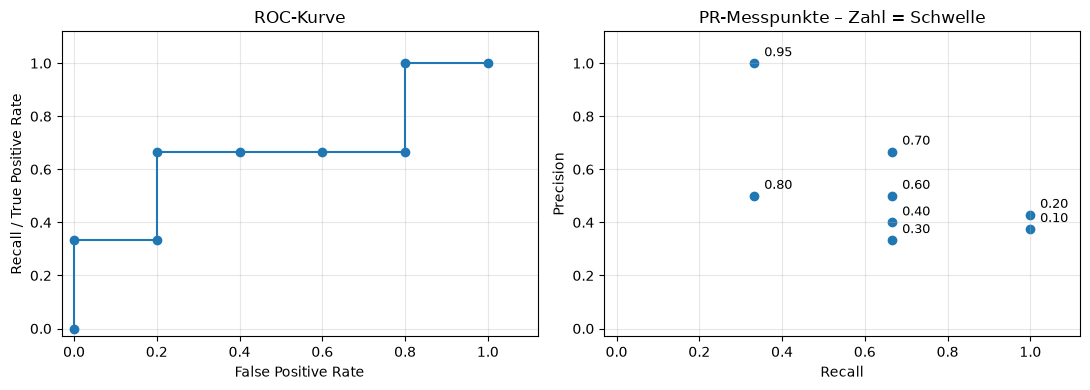

In [4]:
import matplotlib.pyplot as plt

fpr_werte = [zeile[1] for zeile in ergebnisse]
recall_werte = [zeile[2] for zeile in ergebnisse]
precision_werte = [zeile[3] for zeile in ergebnisse]

fig, achsen = plt.subplots(1, 2, figsize=(11, 4))

# Links: ROC-Kurve wie bisher
achsen[0].plot([0] + fpr_werte, [0] + recall_werte, marker="o")
achsen[0].set_title("ROC-Kurve")
achsen[0].set_xlabel("False Positive Rate")
achsen[0].set_ylabel("Recall / True Positive Rate")

# Rechts: PR-Messpunkte ohne Verbindungslinien
achsen[1].scatter(recall_werte, precision_werte)

# Jeden Punkt mit seiner Entscheidungsschwelle beschriften
for schwelle, fpr, recall, precision in ergebnisse:
    achsen[1].annotate(
        f"{schwelle:.2f}",
        (recall, precision),
        xytext=(7, 5),
        textcoords="offset points",
        fontsize=9
    )

achsen[1].set_title("PR-Messpunkte – Zahl = Schwelle")
achsen[1].set_xlabel("Recall")
achsen[1].set_ylabel("Precision")

for achse in achsen:
    achse.set_xlim(-0.03, 1.12)
    achse.set_ylim(-0.03, 1.12)
    achse.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
y_selten = []
scores_selten = []

# Negative Fälle samt ihrem Score vervielfachen
for wahr, score in zip(y_true, scores):
    anzahl = 20 if wahr == 0 else 1
    y_selten.extend([wahr] * anzahl)
    scores_selten.extend([score] * anzahl)

# Bewusst festsetzen: nicht den letzten Schleifenwert übernehmen
vergleichsschwelle = 0.5

for name, labels, modell_scores in [
    ("Bisherige Verteilung", y_true, scores),
    ("Seltene positive Fälle", y_selten, scores_selten)
]:
    vorhersagen = [int(s >= vergleichsschwelle) for s in modell_scores]

    tp = sum(w == 1 and p == 1 for w, p in zip(labels, vorhersagen))
    fp = sum(w == 0 and p == 1 for w, p in zip(labels, vorhersagen))
    fn = sum(w == 1 and p == 0 for w, p in zip(labels, vorhersagen))
    tn = sum(w == 0 and p == 0 for w, p in zip(labels, vorhersagen))

    print(f"\n{name} – Schwelle {vergleichsschwelle}")
    print(f"Positive Fälle: {sum(labels)} von {len(labels)}")
    print(f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"Precision: {tp / (tp + fp):.1%}")
    print(f"Recall: {tp / (tp + fn):.1%}")
    print(f"False Positive Rate: {fp / (fp + tn):.1%}")


Bisherige Verteilung – Schwelle 0.5
Positive Fälle: 3 von 8
TP=2, FP=2, FN=1, TN=3
Precision: 50.0%
Recall: 66.7%
False Positive Rate: 40.0%

Seltene positive Fälle – Schwelle 0.5
Positive Fälle: 3 von 103
TP=2, FP=40, FN=1, TN=60
Precision: 4.8%
Recall: 66.7%
False Positive Rate: 40.0%


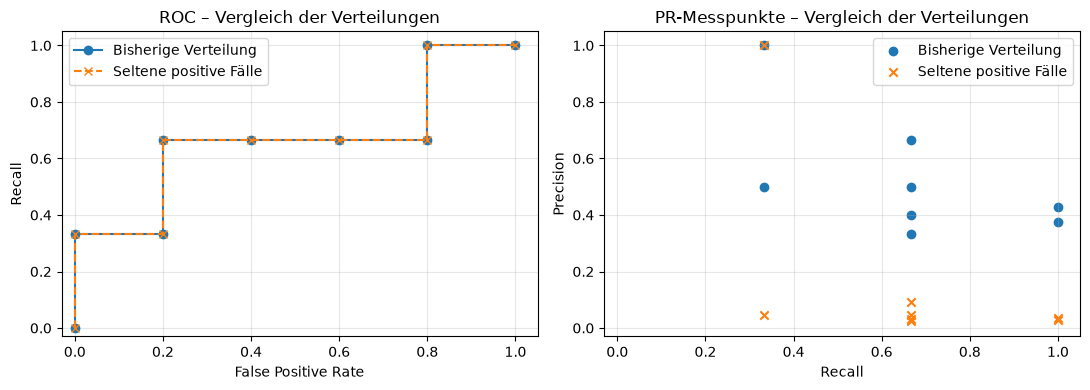

In [6]:
import matplotlib.pyplot as plt

# Gleiche Berechnung wie bisher, für beliebige unserer Datensätze
def kurvenpunkte(labels, modell_scores):
    punkte = []

    for schwelle in sorted(set(modell_scores), reverse=True):
        vorhersagen = [int(s >= schwelle) for s in modell_scores]

        tp = sum(w == 1 and p == 1 for w, p in zip(labels, vorhersagen))
        fp = sum(w == 0 and p == 1 for w, p in zip(labels, vorhersagen))
        fn = sum(w == 1 and p == 0 for w, p in zip(labels, vorhersagen))
        tn = sum(w == 0 and p == 0 for w, p in zip(labels, vorhersagen))

        punkte.append((
            schwelle,
            fp / (fp + tn),
            tp / (tp + fn),
            tp / (tp + fp)
        ))

    return punkte

punkte_bisher = kurvenpunkte(y_true, scores)
punkte_selten = kurvenpunkte(y_selten, scores_selten)

fig, achsen = plt.subplots(1, 2, figsize=(11, 4))

for punkte, name, stil, marker in [
    (punkte_bisher, "Bisherige Verteilung", "-", "o"),
    (punkte_selten, "Seltene positive Fälle", "--", "x")
]:
    fpr_werte = [zeile[1] for zeile in punkte]
    recall_werte = [zeile[2] for zeile in punkte]
    precision_werte = [zeile[3] for zeile in punkte]

    achsen[0].plot(
        [0] + fpr_werte, [0] + recall_werte,
        linestyle=stil, marker=marker, label=name
    )
    achsen[1].scatter(
        recall_werte, precision_werte,
        marker=marker, label=name
    )

achsen[0].set(
    title="ROC – Vergleich der Verteilungen",
    xlabel="False Positive Rate", ylabel="Recall"
    )
achsen[1].set(
    title="PR-Messpunkte – Vergleich der Verteilungen",
    xlabel="Recall", ylabel="Precision"
)

for achse in achsen:
    achse.set_xlim(-0.03, 1.05)
    achse.set_ylim(-0.03, 1.05)
    achse.grid(alpha=0.3)
    achse.legend()

plt.tight_layout()
plt.show()

In [7]:
# Absichtliche Baseline: immer "kein Objekt" vorhersagen
baseline_pred = [0] * len(y_selten)

baseline_accuracy = sum(
    w == p for w, p in zip(y_selten, baseline_pred)
) / len(y_selten)

baseline_recall = sum(
    w == 1 and p == 1 for w, p in zip(y_selten, baseline_pred)
) / sum(y_selten)

print(f"Accuracy: {baseline_accuracy:.1%}")
print(f"Recall: {baseline_recall:.1%}")

Accuracy: 97.1%
Recall: 0.0%


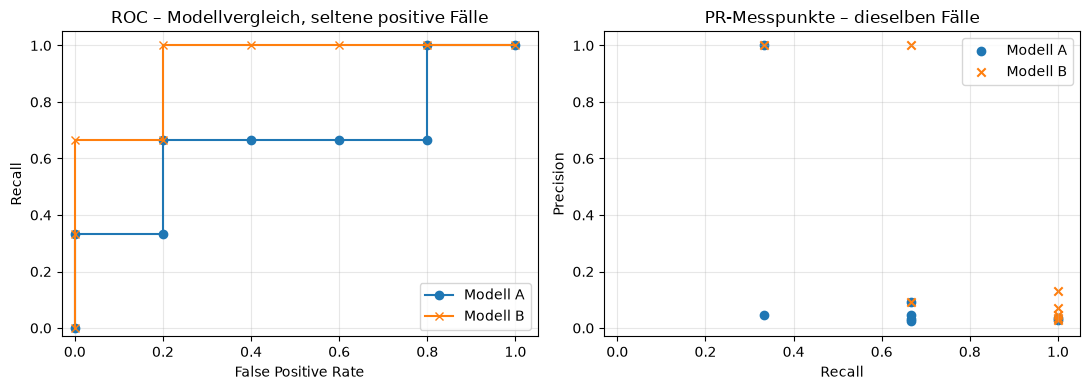

In [8]:
import matplotlib.pyplot as plt

# Zweite simulierte Scorequelle, kein trainiertes Modell.
# Gleiche Bildreihenfolge wie in y_true!
scores_b = [0.90, 0.65, 0.85, 0.55, 0.30, 0.20, 0.60, 0.10]

# Dieselbe Wiederholungsregel wie bei Modell A
scores_b_selten = []

for wahr, score in zip(y_true, scores_b):
    anzahl = 20 if wahr == 0 else 1
    scores_b_selten.extend([score] * anzahl)

fig, achsen = plt.subplots(1, 2, figsize=(11, 4))

for name, modell_scores, marker in [
    ("Modell A", scores_selten, "o"),
    ("Modell B", scores_b_selten, "x")
]:
    punkte_modell = kurvenpunkte(y_selten, modell_scores)

    fpr_werte = [zeile[1] for zeile in punkte_modell]
    recall_werte = [zeile[2] for zeile in punkte_modell]
    precision_werte = [zeile[3] for zeile in punkte_modell]

    achsen[0].plot(
        [0] + fpr_werte, [0] + recall_werte,
        marker=marker, label=name
    )
    achsen[1].scatter(
        recall_werte, precision_werte,
        marker=marker, label=name
    )

achsen[0].set(
    title="ROC – Modellvergleich, seltene positive Fälle",
    xlabel="False Positive Rate", ylabel="Recall"
)
achsen[1].set(
    title="PR-Messpunkte – dieselben Fälle",
    xlabel="Recall", ylabel="Precision"
)

for achse in achsen:
    achse.set_xlim(-0.03, 1.05)
    achse.set_ylim(-0.03, 1.05)
    achse.grid(alpha=0.3)
    achse.legend()

plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score

zusammenfassung = []

for name, labels, modell_scores in [
    ("A – bisherige Verteilung", y_true, scores),
    ("A – seltene positive Fälle", y_selten, scores_selten),
    ("B – bisherige Verteilung", y_true, scores_b),
    ("B – seltene positive Fälle", y_selten, scores_b_selten)
]:
    roc_auc = roc_auc_score(labels, modell_scores)
    ap = average_precision_score(labels, modell_scores, pos_label=1)

    zusammenfassung.append((name, roc_auc, ap))

    print(f"\n{name}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"Average Precision (AP): {ap:.4f}")


A – bisherige Verteilung
ROC-AUC: 0.6667
Average Precision (AP): 0.6984

A – seltene positive Fälle
ROC-AUC: 0.6667
Average Precision (AP): 0.3757

B – bisherige Verteilung
ROC-AUC: 0.9333
Average Precision (AP): 0.9167

B – seltene positive Fälle
ROC-AUC: 0.9333
Average Precision (AP): 0.7101


## Nächster Arbeitsschritt: Ergebnisse einordnen

Die Abbildungen und Kennzahlen sind berechnet. Für die Abgabe müssen wir noch gemeinsam festhalten:

- In welcher Anwendung wird die positive Klasse gesucht und was wiegt schwerer: ein übersehener positiver Fall oder ein Fehlalarm?
- Welche Metriken und welche Entscheidungsschwelle empfehlen wir für **diese** Anwendung – und warum reicht Accuracy allein nicht?
- Welche Grenzen hat der Versuch mit nur acht ursprünglichen Fällen und wiederholten Negativen?
- Welche Quellen stützen Metrikdefinitionen und Schlussfolgerung?

**Wichtig:** Average Precision (AP) ist hier der Wert aus `average_precision_score`, nicht Precision bei einer einzelnen Schwelle und nicht automatisch eine trapezförmige PR-Fläche. Ein hoher ROC-AUC-Wert legt keine optimale Schwelle fest.